In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('train.csv')
df.shape

(404290, 6)

In [5]:
df.sample(5)

,id,qid1,qid2,question1,question2,is_duplicate
368391,368391,103302,498753,Do we understand the mechanisms of life on ear...,The earth is a life-bearing planet because of ...,0
150660,150660,237080,237081,"I have an exam in 3 hours but havent slept, sh...",I can't sleep. During exam time it takes me 2-...,0
399343,399343,48712,28797,Daniel Ek: Why hasn't Spotify come to India ye...,Daniel Ek: When is Spotify coming to India?,1
65551,65551,113746,31112,How do you stop a Cocker Spaniel/Beagle mix fr...,How do you stop a Rottweiler/Pitbull mix from ...,1
138312,138312,220272,114425,What are the best investment avenues in presen...,Can a full time employee be successful in inve...,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 404290 entries, 0 to 404289
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   id            404290 non-null  int64
 1   qid1          404290 non-null  int64
 2   qid2          404290 non-null  int64
 3   question1     404289 non-null  str  
 4   question2     404288 non-null  str  
 5   is_duplicate  404290 non-null  int64
dtypes: int64(4), str(2)
memory usage: 64.8 MB


In [9]:
df.isnull().sum()

id              0
qid1            0
qid2            0
question1       1
question2       2
is_duplicate    0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

is_duplicate
0    255027
1    149263
Name: count, dtype: int64
is_duplicate
0    63.080215
1    36.919785
Name: count, dtype: float64


<Axes: xlabel='is_duplicate'>

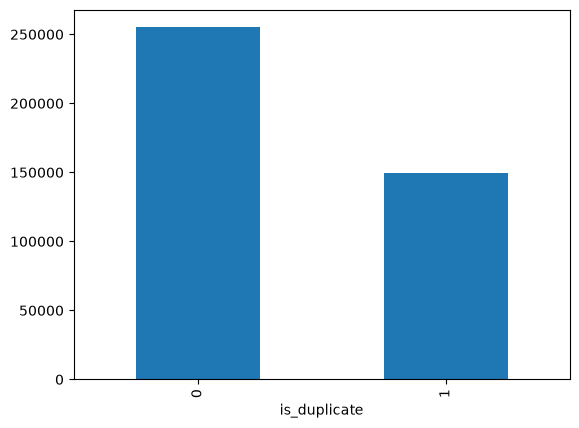

In [13]:
# Distribution of duplicate and non-duplicate questions

print(df['is_duplicate'].value_counts())
print((df['is_duplicate'].value_counts()/df['is_duplicate'].count())*100)
df['is_duplicate'].value_counts().plot(kind='bar')

In [14]:
# Repeated questions

qid = pd.Series(df['qid1'].tolist() + df['qid2'].tolist())
print('Number of unique questions',np.unique(qid).shape[0])
x = qid.value_counts()>1
print('Number of questions getting repeated',x[x].shape[0])

Number of unique questions 537933
Number of questions getting repeated 111780


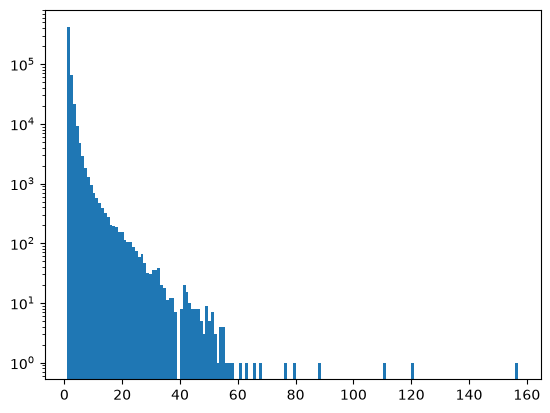

In [15]:
# Repeated questions histogram

plt.hist(qid.value_counts().values,bins=160)
plt.yscale('log')
plt.show()